# 01 — EDA y Preparación de Datos
**Proyecto:** LogiSmart — Predicción de retrasos en entregas de última milla  
**Tareas WBS cubiertas:** 1.2.1, 1.2.2, 1.2.3 (exploración y diagnóstico) + 1.3.1, 1.3.2 (preparación)  
**Responsable:** Data Engineer  
**Entrada:** `data/logismart_entregas_sinteticas.csv` (180.000 registros)

Se fusionan exploración y preparación en un solo notebook para no bloquear el modelado (Persona 2) dado el plazo acotado de esta entrega. El balanceo de clases (SMOTE) **no se aplica aquí**: corresponde a la tarea 1.4.2, dentro del notebook de modelado, porque es una decisión sobre el entrenamiento, no sobre la calidad de los datos crudos.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import hashlib
import os

pd.set_option('display.max_columns', None)
plt.rcParams['figure.figsize'] = (8, 4)

os.makedirs("data", exist_ok=True)

df = pd.read_csv('data/logismart_entregas_sinteticas.csv', parse_dates=['fecha'])
print(f'Shape: {df.shape[0]:,} filas x {df.shape[1]} columnas')
df.head()

Shape: 180,000 filas x 19 columnas


,id_entrega,fecha,hora_programada,comuna_origen,comuna_destino,distancia_estimada_km,tipo_vehiculo,id_conductor,experiencia_conductor_anios,cantidad_paquetes,peso_kg,volumen_m3,duracion_estimada_min,duracion_real_min,cantidad_paradas,hora_salida_real,incidencias,estado_final,retraso
0,ENT-000000,2026-07-22,11:46,Viña del Mar,Providencia,33.8,Camioneta,COND-0142,8,20,28.7,0.793,97.0,100.0,1,12:11,Ninguna,A tiempo,0
1,ENT-000001,2026-09-05,08:50,Las Condes,Valparaíso,6.3,Furgón,COND-0097,14,39,132.7,3.885,32.0,36.0,6,08:15,Ninguna,A tiempo,0
2,ENT-000002,2026-10-16,08:41,Valparaíso,Viña del Mar,17.1,Camioneta,COND-0024,8,33,40.9,0.834,42.0,41.0,2,08:41,Ninguna,A tiempo,0
3,ENT-000003,2026-09-12,14:11,Viña del Mar,San Pedro,16.9,Furgón,COND-0079,8,10,30.5,0.797,66.0,73.0,4,14:12,Ninguna,A tiempo,0
4,ENT-000004,2026-06-04,16:21,Santiago,Valparaíso,2.7,Camioneta,COND-0011,10,17,17.6,0.480,18.0,16.0,6,16:27,Ninguna,A tiempo,0


## 1.2.1 — Extracción y exploración inicial

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 180000 entries, 0 to 179999
Data columns (total 19 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   id_entrega                   180000 non-null  str           
 1   fecha                        180000 non-null  datetime64[us]
 2   hora_programada              180000 non-null  str           
 3   comuna_origen                153000 non-null  str           
 4   comuna_destino               180000 non-null  str           
 5   distancia_estimada_km        180000 non-null  float64       
 6   tipo_vehiculo                180000 non-null  str           
 7   id_conductor                 180000 non-null  str           
 8   experiencia_conductor_anios  180000 non-null  int64         
 9   cantidad_paquetes            180000 non-null  int64         
 10  peso_kg                      180000 non-null  float64       
 11  volumen_m3                   180000 n

In [12]:
df.describe(include='number').T

,count,mean,std,min,25%,50%,75%,max
distancia_estimada_km,180000.0,13.020632,8.483674,1.000,6.800,11.100,17.200,98.400
experiencia_conductor_anios,180000.0,6.992433,4.317698,0.000,3.000,7.000,11.000,14.000
cantidad_paquetes,180000.0,19.993733,11.261259,1.000,10.000,20.000,30.000,39.000
peso_kg,180000.0,39.975126,30.054672,0.500,15.900,32.600,58.600,136.500
volumen_m3,180000.0,0.799168,0.666114,0.005,0.288,0.615,1.136,4.042
duracion_estimada_min,180000.0,47.815461,25.109063,4.000,30.000,43.000,60.000,340.000
duracion_real_min,180000.0,51.643372,29.567695,4.000,31.000,45.000,65.000,446.000
cantidad_paradas,180000.0,6.001567,3.165594,1.000,3.000,6.000,9.000,11.000
retraso,180000.0,0.151161,0.358207,0.000,0.000,0.000,0.000,1.000


### Calidad de datos: valores nulos
Se audita el porcentaje de nulos por columna. Se espera encontrar el problema conocido en `comuna_origen` (~15%).

In [13]:
nulos = df.isna().sum().sort_values(ascending=False)
nulos_pct = (df.isna().mean() * 100).round(2)
pd.DataFrame({'nulos': nulos, 'pct': nulos_pct}).query('nulos > 0')

,nulos,pct
comuna_origen,27000,15.0


## 1.2.2 — EDA de variables operacionales

Tasa de retraso global: 15.1%


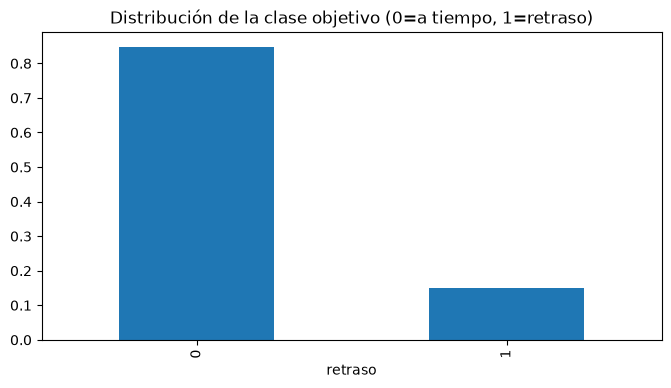

In [14]:
tasa_retraso = df['retraso'].mean()
print(f'Tasa de retraso global: {tasa_retraso:.1%}')
df['retraso'].value_counts(normalize=True).plot(kind='bar', title='Distribución de la clase objetivo (0=a tiempo, 1=retraso)')
plt.show()

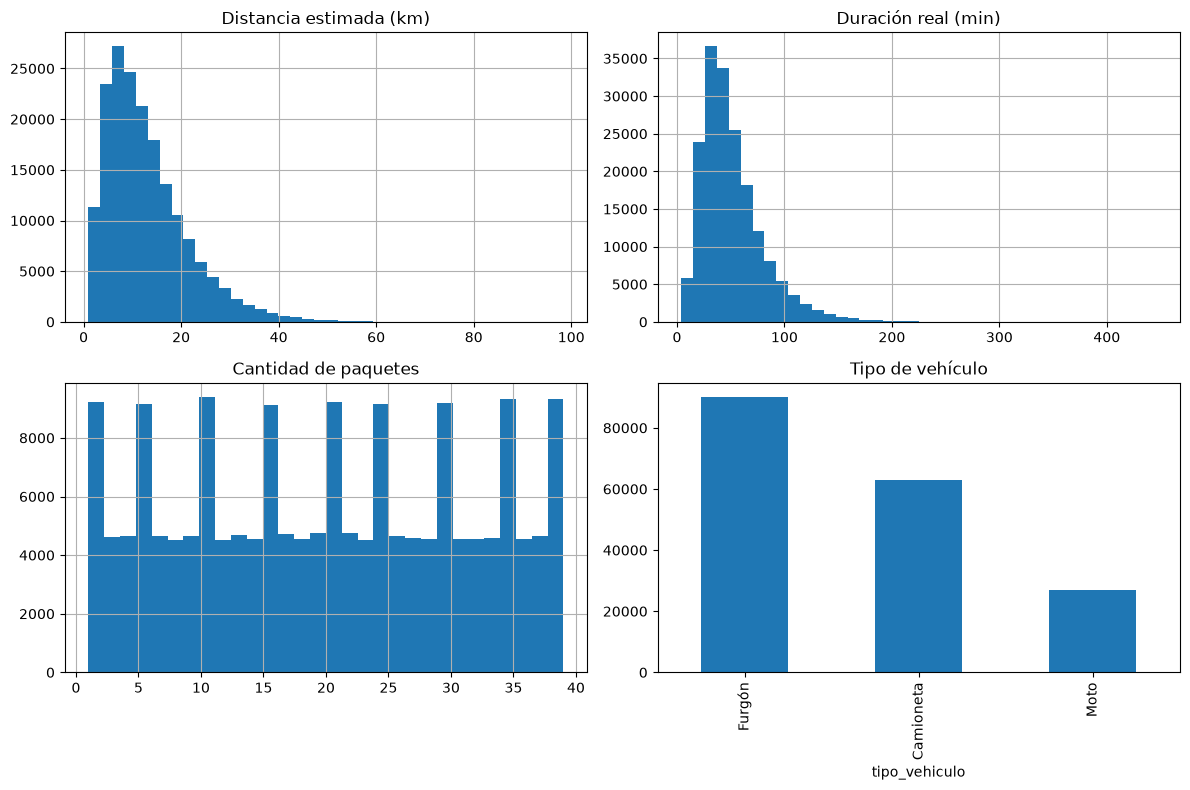

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
df['distancia_estimada_km'].hist(bins=40, ax=axes[0,0]); axes[0,0].set_title('Distancia estimada (km)')
df['duracion_real_min'].hist(bins=40, ax=axes[0,1]); axes[0,1].set_title('Duración real (min)')
df['cantidad_paquetes'].hist(bins=30, ax=axes[1,0]); axes[1,0].set_title('Cantidad de paquetes')
df['tipo_vehiculo'].value_counts().plot(kind='bar', ax=axes[1,1]); axes[1,1].set_title('Tipo de vehículo')
plt.tight_layout()
plt.show()

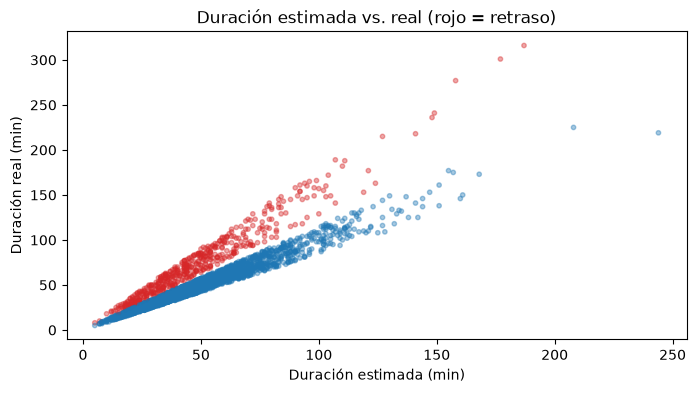

In [16]:
muestra = df.sample(3000, random_state=1)
colores = muestra['retraso'].map({0: 'tab:blue', 1: 'tab:red'})
plt.scatter(muestra['duracion_estimada_min'], muestra['duracion_real_min'], c=colores, alpha=0.4, s=10)
plt.xlabel('Duración estimada (min)'); plt.ylabel('Duración real (min)')
plt.title('Duración estimada vs. real (rojo = retraso)')
plt.show()

## 1.2.3 — Diagnóstico de sesgo por comuna

In [17]:
comunas_perifericas = ['Til Til', 'Melipilla', 'Quilpué', 'Casablanca', 'San Pedro']

resumen_comuna = (
    df.assign(es_periferica=df['comuna_origen'].isin(comunas_perifericas) | df['comuna_destino'].isin(comunas_perifericas))
      .groupby('es_periferica')
      .agg(n_registros=('id_entrega', 'count'), tasa_retraso=('retraso', 'mean'))
)
resumen_comuna.index = resumen_comuna.index.map({False: 'Comunas núcleo', True: 'Comunas periféricas'})
resumen_comuna['pct_del_total'] = (resumen_comuna['n_registros'] / len(df) * 100).round(1)
resumen_comuna

,n_registros,tasa_retraso,pct_del_total
es_periferica,,,
Comunas núcleo,154364,0.120255,85.8
Comunas periféricas,25636,0.337260,14.2


In [18]:
por_comuna = (
    df.dropna(subset=['comuna_origen'])
      .groupby('comuna_origen')
      .agg(n_registros=('id_entrega', 'count'), tasa_retraso=('retraso', 'mean'))
      .sort_values('n_registros')
)
por_comuna

,n_registros,tasa_retraso
comuna_origen,,
Casablanca,2393,0.340159
San Pedro,2409,0.337484
Til Til,2462,0.323721
Quilpué,2479,0.330375
Melipilla,2508,0.355263
Ñuñoa,17466,0.135463
Santiago,17498,0.133958
Valparaíso,17513,0.134871
Maipú,17573,0.132760


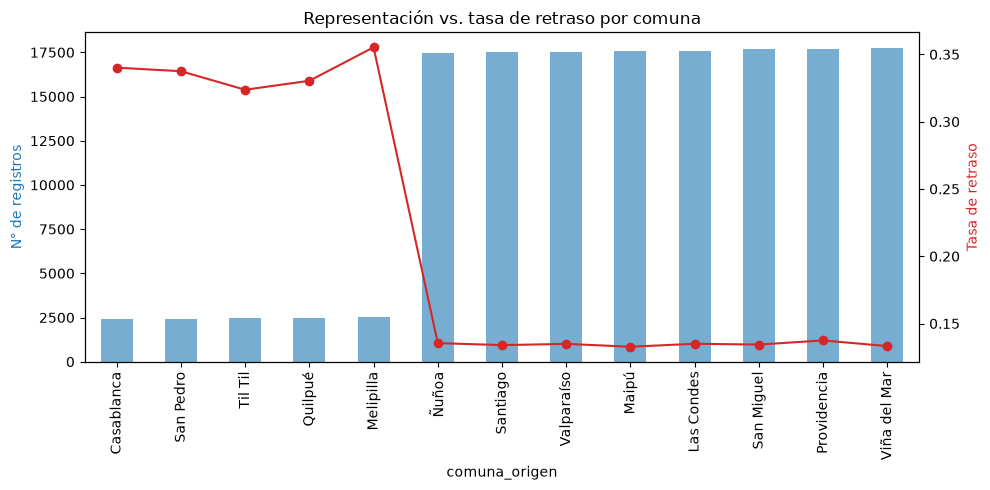

In [19]:
fig, ax1 = plt.subplots(figsize=(10, 5))
por_comuna['n_registros'].plot(kind='bar', ax=ax1, color='tab:blue', alpha=0.6)
ax1.set_ylabel('N° de registros', color='tab:blue')
ax2 = ax1.twinx()
ax2.plot(range(len(por_comuna)), por_comuna['tasa_retraso'], color='tab:red', marker='o')
ax2.set_ylabel('Tasa de retraso', color='tab:red')
plt.title('Representación vs. tasa de retraso por comuna')
plt.tight_layout()
plt.show()

Los 10 conductores con más rutas concentran el 25.5% de las entregas totales


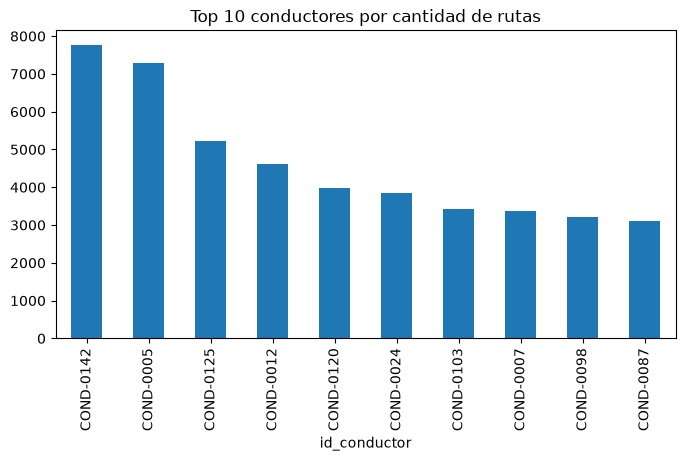

In [20]:
rutas_por_conductor = df['id_conductor'].value_counts()
top10_pct = rutas_por_conductor.head(10).sum() / len(df) * 100
print(f'Los 10 conductores con más rutas concentran el {top10_pct:.1f}% de las entregas totales')
rutas_por_conductor.head(10).plot(kind='bar', title='Top 10 conductores por cantidad de rutas')
plt.show()

## 1.3.1 — Tratamiento de valores faltantes (`comuna_origen`)

**Supuesto declarado:** no existe en el caso un criterio oficial de imputación, por lo que el equipo adopta como supuesto razonable que la comuna de origen de una entrega suele coincidir o ser cercana a la comuna de destino habitual de esa ruta (zonas de reparto geográficamente concentradas). Se imputa `comuna_origen` faltante con la **moda de `comuna_destino` para ese mismo registro cuando aplica, y si no, con la moda global de `comuna_origen`**. Se documenta como supuesto explícito, no como dato verificado del caso.

In [21]:
moda_global_origen = df['comuna_origen'].mode()[0]

mask_nulo = df['comuna_origen'].isna()
print(f'Registros con comuna_origen nula antes de imputar: {mask_nulo.sum():,}')

df.loc[mask_nulo, 'comuna_origen'] = df.loc[mask_nulo, 'comuna_destino'].fillna(moda_global_origen)

print(f'Registros con comuna_origen nula después de imputar: {df["comuna_origen"].isna().sum()}')

Registros con comuna_origen nula antes de imputar: 27,000
Registros con comuna_origen nula después de imputar: 0


## 1.3.2 — Pseudonimización del identificador del conductor

Conforme a RNF-02 y a la corrección técnica de EP1: se usa **hash criptográfico con sal (salted hash)**, no SHA-256 plano, porque con un espacio pequeño y predecible de IDs (150 conductores) un hash sin sal es vulnerable a ataques de fuerza bruta / tablas precalculadas (rainbow tables). La sal se mantiene fuera del dataset exportado (simulada aquí como constante de proyecto, en producción debe vivir en un gestor de secretos, no en el repositorio).

In [22]:
SALT = 'logismart_ep5_2026_proyecto_salt'  # en producción: variable de entorno / secret manager, nunca en el repo

def hash_salado(valor: str) -> str:
    return hashlib.sha256((valor + SALT).encode('utf-8')).hexdigest()[:16]

df['id_conductor_hash'] = df['id_conductor'].apply(hash_salado)
df = df.drop(columns=['id_conductor'])

print(f'Conductores únicos tras hash: {df["id_conductor_hash"].nunique()} (antes: 150 esperados)')
df[['id_conductor_hash']].head()

Conductores únicos tras hash: 150 (antes: 150 esperados)


,id_conductor_hash
0,b5283c4d7dac26bc
1,cc2cbd37eff62218
2,974b1088ca91e7a9
3,3b4bef880b3a384c
4,5d819c8430fbedaa


## 1.3.3 / 1.3.4 — Nota
La ingeniería de variables operacionales adicionales y el balanceo muestral/partición Train-Validation-Test se dejan para el notebook de modelado (`02_modelado.ipynb`), ya que dependen de las decisiones de split y de la técnica de balanceo (SMOTE) que se evaluará junto con el baseline — evitando fijar el partición antes de conocer el pipeline de entrenamiento.

## Exportación del dataset preparado

In [25]:
df.to_csv('data/logismart_entregas_preparado.csv', index=False)
print(f'Dataset preparado exportado: {df.shape[0]:,} filas x {df.shape[1]} columnas')
print('Sin id_conductor en texto plano, sin nulos en comuna_origen.')

Dataset preparado exportado: 180,000 filas x 19 columnas
Sin id_conductor en texto plano, sin nulos en comuna_origen.


## Conclusiones (insumo para Fase 4 — Modelado)

1. Nulos de `comuna_origen` resueltos mediante imputación declarada (supuesto explícito, no dato del caso).
2. `id_conductor` pseudonimizado con hash salado; columna original eliminada del dataset exportado.
3. Sesgo de muestreo confirmado: comunas periféricas con muchos menos registros y tasa de retraso    notablemente más alta — riesgo **R2** de la matriz EP1/EP3, que el modelo probablemente heredará como    bajo recall en esos segmentos. Queda documentado como punto de partida esperado para la tarea 1.4.2.
4. `data/logismart_entregas_preparado.csv` queda listo como entrada única para `02_modelado.ipynb`.